# Classification des maladies du riz : préparation des données avec Spark

Cours : Fondements et Applications du Big Data — TP 3, partie big
Auteur : Antoine Chiausa

## Introduction

On reprend le notebook Kaggle `rice-disease-dataset.ipynb`, qui classe des photos de feuilles de riz en six catégories (cinq maladies et les feuilles saines) avec un réseau EfficientNetB0 pré-entraîné. Les images viennent de deux datasets Kaggle, [Rice Leaf Diseases](https://www.kaggle.com/datasets/ngivitgccychui/rice-leaf-diseases-dataset-vbookshelf) et [Rice Disease Dataset](https://www.kaggle.com/datasets/anshulm257/rice-disease-dataset), soit environ 4 000 fichiers et 1 Go.

Les parties 1 à 5 (EDA, pré-traitement et transformation) sont faites avec Spark. Elles remplacent la première cellule du notebook de base, qui copiait les fichiers avec `shutil`. Les parties 6 à 8 (modèle, évaluation et sauvegarde) sont celles du notebook de base, sans modification.

## 1. Environnement Spark

Spark 4 a besoin de Java 17 ou 21. Sur Mac, on sélectionne Java 17 avec `java_home` ; sur Kaggle, pyspark et Java sont installés s'ils manquent.

In [31]:
import importlib.util, io, os, shutil, subprocess, sys, time
from pathlib import Path

if importlib.util.find_spec("pyspark") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyspark"], check=True)
if os.path.exists("/usr/libexec/java_home"):  # Mac : Spark ne démarre pas avec le Java par défaut (Java 27)
    os.environ["JAVA_HOME"] = subprocess.run(["/usr/libexec/java_home", "-v", "17"], capture_output=True, text=True).stdout.strip()
elif shutil.which("java") is None:
    subprocess.run("apt-get update -qq && apt-get install -y -qq openjdk-17-jre-headless", shell=True, check=True)
os.environ["PYSPARK_PYTHON"] = sys.executable  # les workers Python de Spark utilisent le même interpréteur

import pandas as pd
from PIL import Image
from pyspark.sql import SparkSession, functions as F

spark = (SparkSession.builder.master("local[*]").appName("rice-disease")
         .config("spark.driver.memory", "8g")
         .config("spark.sql.execution.arrow.maxRecordsPerBatch", 64)  # lots de 64 images envoyés aux UDF pandas
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print("Spark", spark.version, "-", spark.sparkContext.defaultParallelism, "cœurs")

Spark 4.2.0 - 8 cœurs


Paramètres repris de la première cellule du notebook de base, avec les chemins adaptés aux données du dossier `data/`.

In [32]:
import os, shutil

dataset1 = "data/Rice Leaf Diseases Dataset-vbookshelf"
dataset2 = "data/Rice_Leaf_AUG"

output_dir = "data/combined_dataset"

classes = [
    "Bacterial_leaf_blight",
    "Brown_spot",
    "Leaf_blast",
    "Sheath_blight",
    "Leaf_scald",
    "Healthy"
]

mapping = {
    "Bacterial leaf blight": "Bacterial_leaf_blight",
    "Brown spot": "Brown_spot",

    "Bacterial Leaf Blight": "Bacterial_leaf_blight",
    "Brown Spot": "Brown_spot",
    "Leaf Blast": "Leaf_blast",
    "Sheath Blight": "Sheath_blight",
    "Leaf scald": "Leaf_scald",
    "Healthy Rice Leaf": "Healthy"
}

Les deux datasets sont téléchargés depuis Kaggle dans `data/` s'ils n'y sont pas déjà.

In [33]:
import urllib.request, zipfile

for dossier, nom in [(dataset1, "ngivitgccychui/rice-leaf-diseases-dataset-vbookshelf"),
                     (dataset2, "anshulm257/rice-disease-dataset")]:
    if not os.path.exists(dossier):
        archive, _ = urllib.request.urlretrieve(f"https://www.kaggle.com/api/v1/datasets/download/{nom}")
        zipfile.ZipFile(archive).extractall("data")
        os.remove(archive)
    print(dossier, ":", sum(f.is_file() for f in Path(dossier).rglob("*")), "fichiers")

data/Rice Leaf Diseases Dataset-vbookshelf : 120 fichiers
data/Rice_Leaf_AUG : 3829 fichiers


## 2. Lecture des images

Spark lit les fichiers avec la source `binaryFile` : une ligne par fichier, avec son chemin, sa taille et son contenu. La classe d'origine est le nom du dossier qui contient l'image.

In [34]:
def lire(dossier, source):
    return (spark.read.format("binaryFile").option("recursiveFileLookup", "true").load(dossier)
            .withColumn("source", F.lit(source))
            .withColumn("classe_origine", F.element_at(F.split("path", "/"), -2)))

images = lire(dataset1, "dataset1").unionByName(lire(dataset2, "dataset2"))
print(images.count(), "fichiers répartis en", images.rdd.getNumPartitions(), "partitions")

3949 fichiers répartis en 135 partitions


Une UDF pandas reçoit le chemin de chaque image et l'ouvre avec PIL pour lire ses dimensions et son mode de couleur ; une image illisible donne des valeurs vides. Envoyer le chemin plutôt que le contenu évite de faire passer les images de Spark vers Python, ce qui provoquait l'erreur `No buffer space available` sur Mac. L'empreinte MD5 du contenu, qui sert à repérer les doublons, est calculée directement par Spark. Ces informations, sans le contenu des images, sont gardées en cache pour l'EDA.

In [35]:
def fichier_local(path):
    return path.removeprefix("file:")  # Spark renvoie des chemins de la forme file:/dossier/image.jpg

@F.pandas_udf("largeur int, hauteur int, mode string")
def infos_image(chemins: pd.Series) -> pd.DataFrame:
    infos = []
    for path in chemins:
        try:
            with Image.open(fichier_local(path)) as image:
                infos.append((image.width, image.height, image.mode))
        except Exception:
            infos.append((None, None, None))
    return pd.DataFrame(infos, columns=["largeur", "hauteur", "mode"])

meta = (images.select("path", "length", "source", "classe_origine",
                      F.lower(F.substring_index("path", ".", -1)).alias("extension"),
                      F.md5("content").alias("md5"), infos_image("path").alias("infos"))
        .select("*", "infos.*").drop("infos")
        .cache())
meta.drop("path").show(5)

+-------+--------+--------------------+---------+--------------------+-------+-------+----+
| length|  source|      classe_origine|extension|                 md5|largeur|hauteur|mode|
+-------+--------+--------------------+---------+--------------------+-------+-------+----+
|2229885|dataset1|           Leaf smut|      jpg|7eac1fe37be94e238...|   4160|   2340| RGB|
| 658844|dataset1|Bacterial leaf bl...|      jpg|cc739d5e35312c0c1...|   3081|    897| RGB|
| 550997|dataset1|Bacterial leaf bl...|      jpg|be5506a72525e7be3...|   3081|    897| RGB|
| 537232|dataset1|Bacterial leaf bl...|      jpg|2ddc8f20bf8753920...|   3081|    897| RGB|
| 527791|dataset1|Bacterial leaf bl...|      jpg|87d8e788225b2f329...|   3081|    897| RGB|
+-------+--------+--------------------+---------+--------------------+-------+-------+----+
only showing top 5 rows


/Users/antoinechiausa/Desktop/Cours/INFO/S9/Big Data/.venv/lib/python3.14/site-packages/pyspark/sql/pandas/functions.py:777: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/Users/antoinechiausa/Desktop/Cours/INFO/S9/Big Data/.venv/lib/python3.14/site-packages/pyspark/sql/pandas/typehints.py:60: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


## 3. EDA

### 3.1 Images par dataset et par classe

In [36]:
(meta.groupBy("source", "classe_origine")
     .agg(F.count("*").alias("images"), F.round(F.sum("length") / 1e6, 1).alias("taille (Mo)"))
     .orderBy("source", "classe_origine")
     .show(truncate=False))

+--------+---------------------+------+-----------+
|source  |classe_origine       |images|taille (Mo)|
+--------+---------------------+------+-----------+
|dataset1|Bacterial leaf blight|40    |17.7       |
|dataset1|Brown spot           |40    |9.8        |
|dataset1|Leaf smut            |40    |12.2       |
|dataset2|Bacterial Leaf Blight|636   |112.5      |
|dataset2|Brown Spot           |646   |134.8      |
|dataset2|Healthy Rice Leaf    |653   |322.6      |
|dataset2|Leaf Blast           |634   |114.8      |
|dataset2|Leaf scald           |628   |67.7       |
|dataset2|Sheath Blight        |632   |315.2      |
+--------+---------------------+------+-----------+



Les deux datasets contiennent 3 949 images réparties dans 9 dossiers. Le premier n'a que 120 images (40 par classe), le second en a 3 829, réparties de façon équilibrée entre 6 classes (environ 630 chacune). Les mêmes maladies n'ont pas exactement le même nom dans les deux datasets (`Brown spot` et `Brown Spot` par exemple), et la classe `Leaf smut` n'existe que dans le premier. Elle n'est pas dans la correspondance du notebook de base et sera donc retirée.

### 3.2 Format et dimensions

In [37]:
meta.groupBy("extension", "mode").count().show()
print("Dimensions différentes :", meta.select("largeur", "hauteur").distinct().count())
meta.groupBy("source", "largeur", "hauteur").count().orderBy(F.desc("count")).show(8)

+---------+----+-----+
|extension|mode|count|
+---------+----+-----+
|      jpg| RGB| 3949|
+---------+----+-----+

Dimensions différentes : 72
+--------+-------+-------+-----+
|  source|largeur|hauteur|count|
+--------+-------+-------+-----+
|dataset2|    224|    224| 2931|
|dataset2|   1600|   1200|  787|
|dataset1|   3081|    897|   85|
|dataset2|   4000|   3000|   37|
|dataset2|   2160|   3840|   17|
|dataset2|   2448|   3264|   15|
|dataset2|   3840|   2160|    9|
|dataset2|   1600|    720|    2|
+--------+-------+-------+-----+
only showing top 8 rows


Toutes les images sont des JPEG en couleur (RGB), mais elles ont 72 dimensions différentes. Les trois quarts du second dataset sont déjà en 224 × 224, ce sont sans doute ses images augmentées, alors que d'autres photos font jusqu'à 4000 × 3000 pixels. Il faut donc ramener toutes les images à la même taille avant l'entraînement.

### 3.3 Images illisibles et doublons

In [38]:
print("Images illisibles :", meta.filter(F.col("largeur").isNull()).count())

doublons = (meta.groupBy("md5")
                .agg(F.count("*").alias("copies"), F.countDistinct("classe_origine").alias("classes"))
                .filter("copies > 1"))
doublons.agg(F.count("*").alias("groupes de doublons"),
             F.sum(F.col("copies") - 1).alias("fichiers en trop"),
             F.max("classes").alias("classes par groupe (max)")).show()

Images illisibles : 0
+-------------------+----------------+------------------------+
|groupes de doublons|fichiers en trop|classes par groupe (max)|
+-------------------+----------------+------------------------+
|                 31|              31|                       1|
+-------------------+----------------+------------------------+



Aucune image n'est illisible. En revanche, 31 images apparaissent deux fois à l'identique, toujours dans la même classe. Si on les garde, une copie peut se retrouver dans l'entraînement et l'autre dans la validation.

### 3.4 Une image par classe d'origine

/Users/antoinechiausa/Desktop/Cours/INFO/S9/Big Data/.venv/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


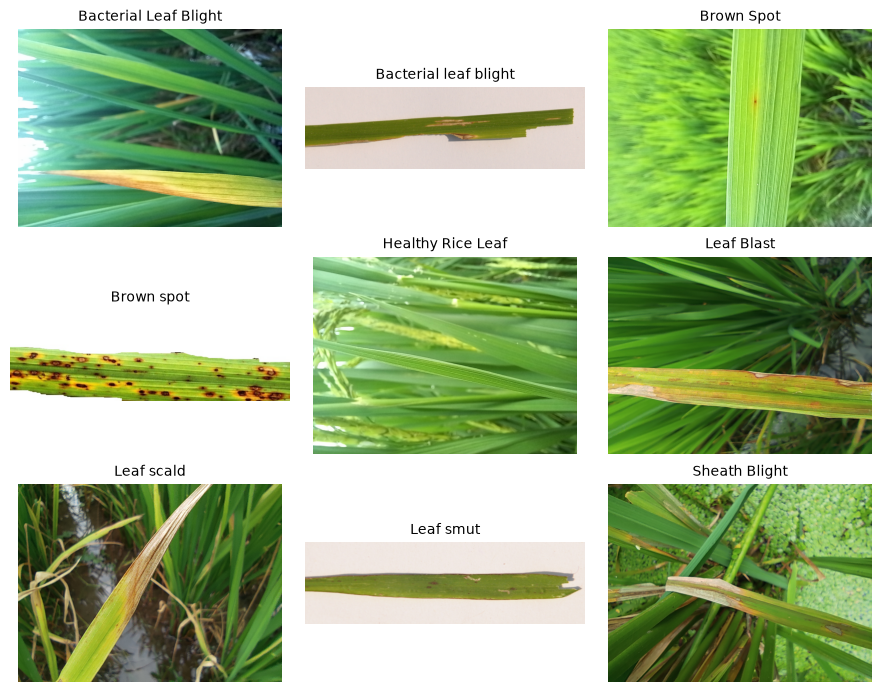

In [39]:
import matplotlib.pyplot as plt

premieres = meta.groupBy("classe_origine").agg(F.min("path").alias("path")).select("path")
exemples = images.join(premieres, "path").select("classe_origine", "content").orderBy("classe_origine").toPandas()

fig, axes = plt.subplots(3, 3, figsize=(9, 7))
for ax, (_, ligne) in zip(axes.flat, exemples.iterrows()):
    ax.imshow(Image.open(io.BytesIO(ligne["content"])))
    ax.set_title(ligne["classe_origine"], fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

Les photos du premier dataset sont prises sur un fond blanc, celles du second directement dans la rizière. Les conditions de prise de vue sont donc très différentes d'un dataset à l'autre.

## 4. Pré-traitement

On applique la correspondance de noms du notebook de base pour obtenir les six classes, puis on retire les images dont la classe n'est pas dans cette correspondance (Leaf smut), les images illisibles et les doublons exacts.

In [40]:
correspondance = F.create_map([F.lit(nom) for paire in mapping.items() for nom in paire])

propres = (meta.withColumn("classe", correspondance[F.col("classe_origine")])
               .filter(F.col("classe").isNotNull() & F.col("largeur").isNotNull())
               .dropDuplicates(["md5"]))

print(propres.count(), "images gardées sur", meta.count())
propres.groupBy("classe").count().orderBy("classe").show(truncate=False)

3878 images gardées sur 3949
+---------------------+-----+
|classe               |count|
+---------------------+-----+
|Bacterial_leaf_blight|676  |
|Brown_spot           |677  |
|Healthy              |650  |
|Leaf_blast           |619  |
|Leaf_scald           |628  |
|Sheath_blight        |628  |
+---------------------+-----+



Il reste 3 878 images : les 40 images de `Leaf smut` et les 31 doublons ont été retirés. Les six classes sont bien équilibrées, avec entre 619 et 677 images chacune.

## 5. Transformation

Chaque image est convertie en RGB, redimensionnée en 300 × 300 pixels (la taille `img_size` utilisée ensuite par le modèle) et enregistrée en JPEG dans `output_dir`, avec un dossier par classe comme dans le notebook de base. Les fichiers sont nommés par leur MD5, ce qui évite d'écraser deux images de même nom venant des deux datasets. Spark répartit ce travail entre les cœurs, partition par partition.

In [41]:
TAILLE = (300, 300)

def ecrire_images(lignes):
    for ligne in lignes:
        with Image.open(fichier_local(ligne.path)) as image:
            image = image.convert("RGB").resize(TAILLE, Image.Resampling.BILINEAR)
            image.save(os.path.join(output_dir, ligne.classe, ligne.md5 + ".jpg"), quality=95)

shutil.rmtree(output_dir, ignore_errors=True)
for cls in classes:
    os.makedirs(os.path.join(output_dir, cls), exist_ok=True)

t0 = time.perf_counter()
propres.select("path", "classe", "md5").foreachPartition(ecrire_images)
print(f"Images transformées en {time.perf_counter() - t0:.0f} s")

Images transformées en 21 s


In [42]:
fichiers = list(Path(output_dir).rglob("*.jpg"))
avant = propres.agg(F.sum("length")).first()[0]
apres = sum(f.stat().st_size for f in fichiers)
print(len(fichiers), "images écrites dans", len(os.listdir(output_dir)), "dossiers de classe")
print(f"Taille : {avant / 1e6:.0f} Mo avant, {apres / 1e6:.0f} Mo après")

spark.stop()

3878 images écrites dans 6 dossiers de classe
Taille : 1065 Mo avant, 130 Mo après


La transformation ne prend que quelques secondes, car Spark traite plusieurs partitions en parallèle. Le redimensionnement fait passer le dataset de 1 065 Mo à 130 Mo, puisque les grandes photos sont réduites en 300 × 300. Dans le notebook de base, les fichiers d'origine étaient copiés tels quels et TensorFlow devait ensuite décoder et redimensionner lui-même les grandes photos.

## 6. Chargement des images et modèle (notebook de base)

Cellules du notebook Kaggle, sans modification à part les chemins `/kaggle/working`, remplacés par le dossier du notebook. Elles lisent les images préparées par Spark dans `output_dir`.

In [44]:
%pip install tensorflow
import tensorflow as tf

img_size = (300, 300)
batch_size = 32

train_ds = tf.keras.preprocessing.image_dataset_from_directory(
    output_dir,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=img_size,
    batch_size=batch_size
)

val_ds = tf.keras.preprocessing.image_dataset_from_directory(
    output_dir,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=img_size,
    batch_size=batch_size
)

class_names = train_ds.class_names
print(class_names)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 245.6/245.6 MB 5.6 MB/s  0:00:41m0:00:0100:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 9.3 MB/s  0:00:01m eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.8/2.8 MB 5.3 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 562.6/562.6 kB 7.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 5.7 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.8/25.8 MB 7.0 MB/s  0:00:03 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 26/26 [tensorflow]6 [tensorflow]ly]]

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
Found 3878 files belonging to 6 classes.
Using 3103 files for training.
Found 3878 files belonging to 6 classes.
Using 775 files for validation.
['Bacterial_leaf_blight', 'Brown_spot', 'Healthy', 'Leaf_blast', 'Leaf_scald', 'Sheat

In [45]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().shuffle(1000).prefetch(AUTOTUNE)
val_ds = val_ds.cache().prefetch(AUTOTUNE)

In [46]:
from tensorflow.keras.applications.efficientnet import EfficientNetB0, preprocess_input

data_aug = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.3),
    tf.keras.layers.RandomZoom(0.3),
    tf.keras.layers.RandomContrast(0.3),
])

base_model = EfficientNetB0(
    input_shape=(300,300,3),
    include_top=False,
    weights='imagenet'
)

base_model.trainable = False

model = tf.keras.Sequential([
    data_aug,
    tf.keras.layers.Lambda(preprocess_input),
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.4),
    tf.keras.layers.Dense(6, activation='softmax')
])

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


In [47]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [48]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(patience=4, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(patience=2)
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)

Epoch 1/10


/Users/antoinechiausa/Desktop/Cours/INFO/S9/Big Data/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


97/97 ━━━━━━━━━━━━━━━━━━━━ 80s 771ms/step - accuracy: 0.5578 - loss: 1.3033 - val_accuracy: 0.6542 - val_loss: 1.0184 - learning_rate: 0.0010
Epoch 2/10
97/97 ━━━━━━━━━━━━━━━━━━━━ 88s 909ms/step - accuracy: 0.7035 - loss: 0.8304 - val_accuracy: 0.7897 - val_loss: 0.6636 - learning_rate: 0.0010
Epoch 3/10
97/97 ━━━━━━━━━━━━━━━━━━━━ 101s 1s/step - accuracy: 0.7428 - loss: 0.7118 - val_accuracy: 0.7974 - val_loss: 0.5479 - learning_rate: 0.0010
Epoch 4/10
97/97 ━━━━━━━━━━━━━━━━━━━━ 93s 957ms/step - accuracy: 0.7741 - loss: 0.6185 - val_accuracy: 0.8465 - val_loss: 0.4630 - learning_rate: 0.0010
Epoch 5/10
97/97 ━━━━━━━━━━━━━━━━━━━━ 94s 970ms/step - accuracy: 0.7899 - loss: 0.5721 - val_accuracy: 0.8361 - val_loss: 0.4610 - learning_rate: 0.0010
Epoch 6/10
97/97 ━━━━━━━━━━━━━━━━━━━━ 100s 1s/step - accuracy: 0.7957 - loss: 0.5514 - val_accuracy: 0.8516 - val_loss: 0.4271 - learning_rate: 0.0010
Epoch 7/10
97/97 ━━━━━━━━━━━━━━━━━━━━ 106s 1s/step - accuracy: 0.8218 - loss: 0.4906 - val_accura

In [49]:
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

In [50]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [52]:
model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10
97/97 ━━━━━━━━━━━━━━━━━━━━ 88s 908ms/step - accuracy: 0.8076 - loss: 0.5161 - val_accuracy: 0.8594 - val_loss: 0.3920
Epoch 2/10
97/97 ━━━━━━━━━━━━━━━━━━━━ 79s 821ms/step - accuracy: 0.8221 - loss: 0.5062 - val_accuracy: 0.8645 - val_loss: 0.3782
Epoch 3/10
97/97 ━━━━━━━━━━━━━━━━━━━━ 80s 829ms/step - accuracy: 0.8131 - loss: 0.4958 - val_accuracy: 0.8697 - val_loss: 0.3649
Epoch 4/10
97/97 ━━━━━━━━━━━━━━━━━━━━ 83s 853ms/step - accuracy: 0.8189 - loss: 0.4820 - val_accuracy: 0.8723 - val_loss: 0.3516
Epoch 5/10
97/97 ━━━━━━━━━━━━━━━━━━━━ 82s 843ms/step - accuracy: 0.8340 - loss: 0.4598 - val_accuracy: 0.8826 - val_loss: 0.3475
Epoch 6/10
97/97 ━━━━━━━━━━━━━━━━━━━━ 85s 874ms/step - accuracy: 0.8340 - loss: 0.4586 - val_accuracy: 0.8839 - val_loss: 0.3366
Epoch 7/10
97/97 ━━━━━━━━━━━━━━━━━━━━ 91s 941ms/step - accuracy: 0.8414 - loss: 0.4526 - val_accuracy: 0.8903 - val_loss: 0.3305
Epoch 8/10
97/97 ━━━━━━━━━━━━━━━━━━━━ 97s 1s/step - accuracy: 0.8308 - loss: 0.4537 - val_accurac

## 7. Évaluation (notebook de base)

In [53]:
model.evaluate(val_ds)

25/25 ━━━━━━━━━━━━━━━━━━━━ 14s 532ms/step - accuracy: 0.8929 - loss: 0.3135


[0.31352293491363525, 0.892903208732605]

In [54]:
import numpy as np

y_true = []
y_pred = []

for images, labels in val_ds:
    preds = model.predict(images)
    preds = np.argmax(preds, axis=1)
    
    y_true.extend(labels.numpy())
    y_pred.extend(preds)

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 784ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 540ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 562ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 508ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 493ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 507ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 574ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 520ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 519ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 632ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 542ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 507ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 515ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 546ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 536ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 514ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 928ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 877ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 485ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 487ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 470ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 524ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 494ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 914ms/step


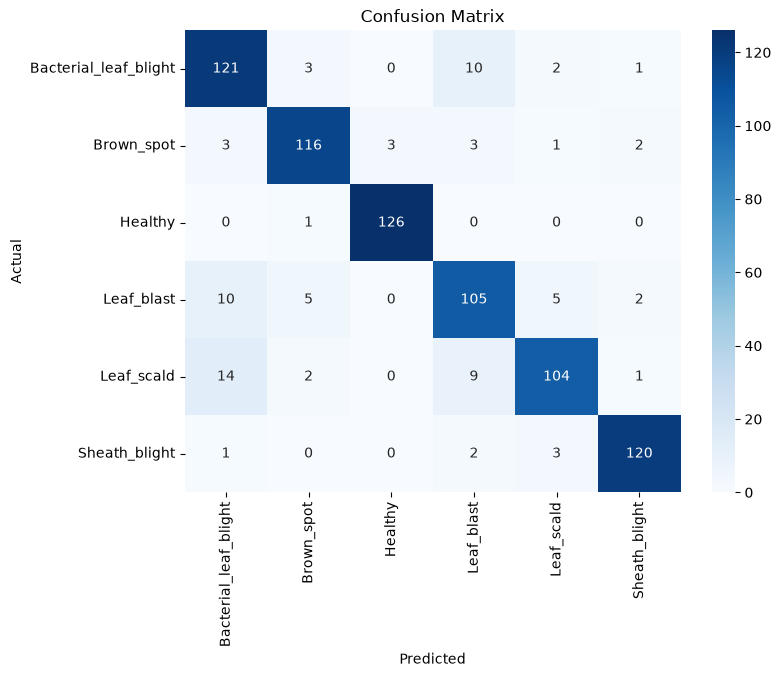

In [55]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [56]:
from sklearn.metrics import classification_report

report = classification_report(y_true, y_pred, target_names=class_names)
print(report)

                       precision    recall  f1-score   support

Bacterial_leaf_blight       0.81      0.88      0.85       137
           Brown_spot       0.91      0.91      0.91       128
              Healthy       0.98      0.99      0.98       127
           Leaf_blast       0.81      0.83      0.82       127
           Leaf_scald       0.90      0.80      0.85       130
        Sheath_blight       0.95      0.95      0.95       126

             accuracy                           0.89       775
            macro avg       0.90      0.89      0.89       775
         weighted avg       0.89      0.89      0.89       775



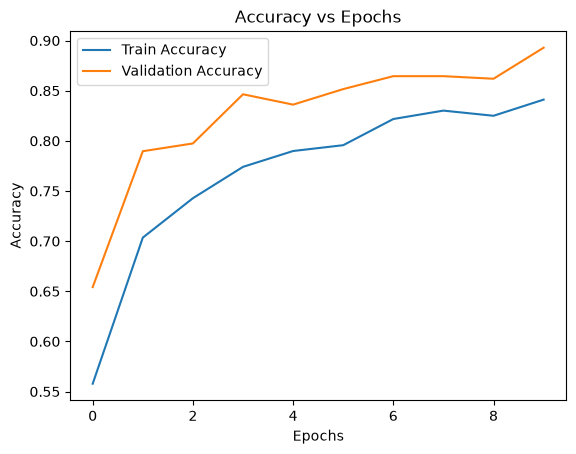

In [57]:
plt.figure()
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.title("Accuracy vs Epochs")
plt.show()

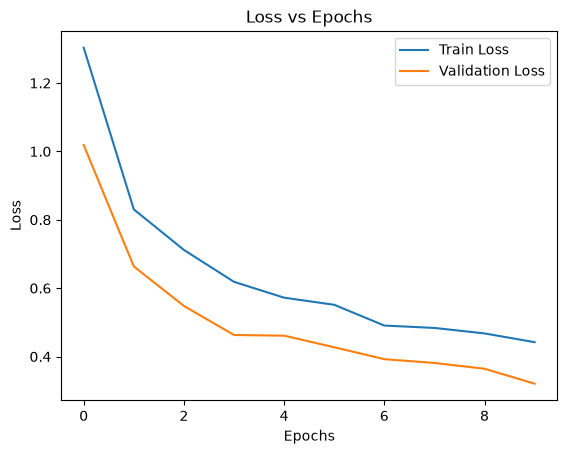

In [58]:
plt.figure()
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.title("Loss vs Epochs")
plt.show()

## 8. Sauvegarde du modèle (notebook de base)

In [59]:
model.save("rice_model.keras")

In [60]:
import os

print(os.listdir("."))

['rice-disease-dataset.ipynb', '.DS_Store', 'rice_model.keras', 'data', 'TP3_rice_disease_big.ipynb']


In [61]:
from tensorflow.keras.models import load_model
from tensorflow.keras.applications.efficientnet import preprocess_input

model = load_model(
    "rice_model.keras",
    custom_objects={"preprocess_input": preprocess_input},
    compile=False
)

In [62]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [63]:
from IPython.display import FileLink

FileLink('rice_model.keras')

/Users/antoinechiausa/Desktop/Cours/INFO/S9/Big Data/TP3/big/rice_model.keras

## Conclusion

- Spark permet de lire les deux datasets d'un coup, d'en faire l'EDA avec des requêtes simples et de préparer les images en parallèle.
- L'EDA montre des noms de classes différents entre les deux datasets, une classe en trop (`Leaf smut`), 72 tailles d'images différentes et 31 doublons exacts.
- Après le pré-traitement et la transformation, il reste 3 878 images en 300 × 300, réparties de façon équilibrée entre les six classes, pour 130 Mo au lieu de 1 Go.
- Le modèle du notebook de base atteint environ 89 % d'accuracy sur la validation. La classe Healthy est la mieux reconnue, Leaf blast la moins bien.